In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Student Performance Analysis Project")
print("All libraries imported successfully!")

Student Performance Analysis Project
All libraries imported successfully!


In [2]:
np.random.seed(42)

students = 200

study_hours = np.random.uniform(1, 10, students)
attendance = np.random.uniform(50, 100, students)
previous_score = np.random.uniform(30, 95, students)
assignments = np.random.randint(1, 11, students)

final_score = (
    3 * study_hours
    + 0.25 * attendance
    + 0.3 * previous_score
    + 1.5 * assignments
    + np.random.normal(0, 5, students)
)

final_score = np.clip(final_score, 0, 100)

data = pd.DataFrame({
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Previous_Score": previous_score,
    "Assignments": assignments,
    "Final_Score": final_score
})

data.head()

,Study_Hours,Attendance,Previous_Score,Assignments,Final_Score
0,4.370861,82.101582,36.703051,5,44.755963
1,9.556429,54.206998,88.665939,2,77.539588
2,7.587945,58.081436,62.841404,10,72.829099
3,6.387926,94.927709,83.719735,6,74.935187
4,2.404168,80.321453,50.803224,5,53.197743


In [3]:
print("Dataset Shape:")
print(data.shape)

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
data.describe()

Dataset Shape:
(200, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     200 non-null    float64
 1   Attendance      200 non-null    float64
 2   Previous_Score  200 non-null    float64
 3   Assignments     200 non-null    int32  
 4   Final_Score     200 non-null    float64
dtypes: float64(4), int32(1)
memory usage: 7.2 KB

Statistical Summary:


,Study_Hours,Attendance,Previous_Score,Assignments,Final_Score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,5.356056,75.218757,63.843731,5.555000,62.386291
std,2.654023,14.650060,19.975072,2.887675,12.361996
min,1.049699,50.253079,30.704447,1.000000,23.382192
25%,3.057242,63.073125,46.608821,3.000000,53.925015
50%,5.450376,77.081994,64.150966,6.000000,62.818027
75%,7.811737,87.109966,82.722468,8.000000,71.164432
max,9.881982,99.525257,94.981649,10.000000,92.943526


In [4]:
# Check missing values
print("Missing Values:")
print(data.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(data.duplicated().sum())

Missing Values:
Study_Hours       0
Attendance        0
Previous_Score    0
Assignments       0
Final_Score       0
dtype: int64

Duplicate Rows:
0


In [5]:
# Remove duplicate rows
data = data.drop_duplicates()

# Fill missing numerical values with column averages
data = data.fillna(data.mean())

print("Data cleaning completed!")
print("Updated dataset shape:", data.shape)

Data cleaning completed!
Updated dataset shape: (200, 5)


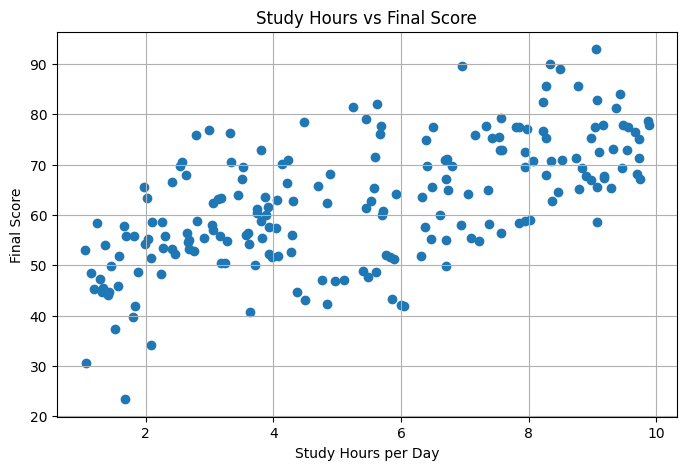

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(data["Study_Hours"], data["Final_Score"])

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours per Day")
plt.ylabel("Final Score")

plt.grid(True)
plt.show()

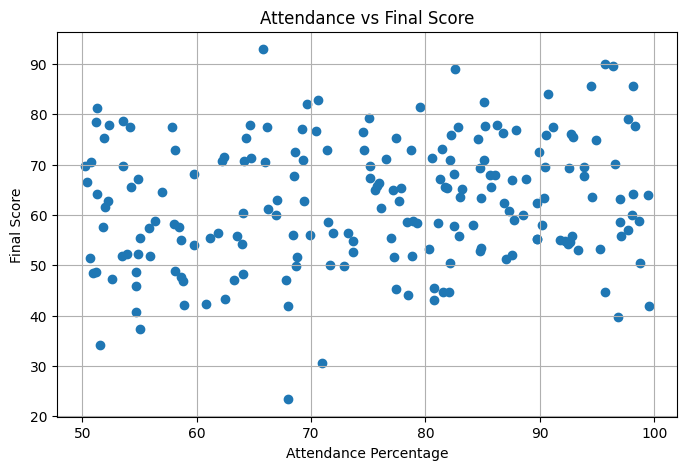

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(data["Attendance"], data["Final_Score"])

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")

plt.grid(True)
plt.show()

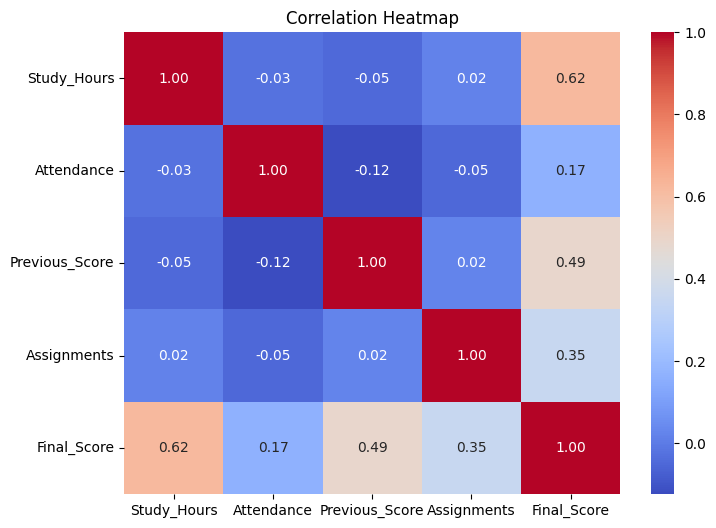

In [8]:
plt.figure(figsize=(8, 6))

correlation = data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [9]:
# Independent variables (input features)
X = data[[
    "Study_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments"
]]

# Dependent variable (target)
y = data["Final_Score"]

print("Input data:")
print(X.head())

print("\nTarget data:")
print(y.head())

Input data:
   Study_Hours  Attendance  Previous_Score  Assignments
0     4.370861   82.101582       36.703051            5
1     9.556429   54.206998       88.665939            2
2     7.587945   58.081436       62.841404           10
3     6.387926   94.927709       83.719735            6
4     2.404168   80.321453       50.803224            5

Target data:
0    44.755963
1    77.539588
2    72.829099
3    74.935187
4    53.197743
Name: Final_Score, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [12]:
y_pred = model.predict(X_test)

print("Actual Scores:")
print(y_test.head())

print("\nPredicted Scores:")
print(y_pred[:5])

Actual Scores:
95     61.393686
15     56.330534
30     55.233589
158    63.174417
128    30.629884
Name: Final_Score, dtype: float64

Predicted Scores:
[62.94101553 54.90227099 63.13749017 62.52401887 36.92086768]


In [13]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Absolute Error: 4.3142022710702985
R2 Score: 0.837967948901037


In [14]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Score": [75],
    "Assignments": [8]
})

predicted_score = model.predict(new_student)

print("Predicted Final Score:", predicted_score[0])

Predicted Final Score: 73.85715242718342


In [15]:
comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

print(comparison.head(10))

   Actual Score  Predicted Score
0     61.393686        62.941016
1     56.330534        54.902271
2     55.233589        63.137490
3     63.174417        62.524019
4     30.629884        36.920868
5     69.322948        65.154522
6     77.827211        79.629402
7     55.519169        59.594184
8     69.746250        75.577888
9     89.690531        83.356389


In [16]:
data.to_csv("student_performance.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
